---
title: "Fit and diagnose rainfall forecasts"
subtitle: "Actual PyCPT CCA/PCR fits · OND and JJA 2023 · full Indonesia"
execute:
  enabled: false
---

This notebook runs **four new fits through PyCPT** using local seasonal inputs:
CCA and PCR for OND and JJA 2023. Reading these executed outputs needs only a
browser. Running all cells requires the **full tested PyCPT fitting environment
and its compatible CPT engine**; the analysis-only environment cannot execute
the fitting calls. No IRI Data Library key or source download is needed.

The first case taught comparison of saved results. Here the learning goals are
to distinguish X/Y/F, run the fitting calls, retain all returned datasets, inspect
model diagnostics, and compare a separate historical forecast with baselines.
The fixed settings are controls, not optimized recommendations. OND and JJA were
selected after observing their results, so they are development examples.
See [setup and downloads](../guides/reproduce.qmd#fitting-case-setup).

## 1. Check the environment and prepared inputs

PyCPT comprises several libraries. We use its direct `cptcore` fitting interface,
as illustrated by the [official core demo](https://github.com/iri-pycpt/notebooks/blob/1c975316910b9e047ce685d9b8cdefb2c4b73551/Demo/cptcore_demo.ipynb).
The small helpers handle provenance, exports and plotting; the fitting calls and
scoring formulas remain visible below. Inputs are prepared seasonal rainfall
totals in mm. Their preparation and source hashes are retained in the kit.

In [1]:
from pathlib import Path
import sys, json, tempfile
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from IPython.display import display, HTML

root = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "pycpt_tutorial").is_dir() and (p / "docs/data/fitting-2023").is_dir()), None)
if root is None:
    raise FileNotFoundError("Open this notebook inside the complete fitting tutorial kit or repository.")
sys.path.insert(0, str(root))
from pycpt_tutorial import fitting as fit, teaching as teach
from pycpt_tutorial.export import save_netcdf
offline = fit.offline_guard()
runtime = fit.preflight()
from cptcore import canonical_correlation_analysis, principal_components_regression
%matplotlib inline
teach.style()
data_dir = root / "docs/data/fitting-2023"
artifacts = root / "docs/assets/fitting-2023"
artifacts.mkdir(parents=True, exist_ok=True)
(root / "temp").mkdir(exist_ok=True)
work = Path(tempfile.mkdtemp(prefix="fitting-2023-", dir=root / "temp"))
provenance = fit.verify_inputs(data_dir)
inputs = {season: fit.prepare_inputs(data_dir, season) for season in fit.SEASONS}
context = fit.load(data_dir / "comparison-context.nc")
results = {season: {} for season in fit.SEASONS}
display(pd.DataFrame([runtime]).drop(columns=["engine_directory", "engine_sha256"]))
print(f"Verified {len(provenance['outputs'])} local files. Each execution uses a new scratch directory.")

,python,pycpt,python_package_metadata,cptio,cptio_python_metadata,wrapper_hashes,engine
0,3.12.5,2.10.4,2.10.4.dev0,1.4.0,1.4.0,"{""cca"": ""938e2969bbbca4383657374f0c0ecec3cf275...",CPT 17.8.3


Verified 26 local files. Each execution uses a new scratch directory.


**X** is the model rainfall used for training, **Y** is the corresponding observed
rainfall, and **F** is the model rainfall for the new target. Training X and Y share
30 seasonal target dates from 1991–2020. F contains one 2023 target per season.
The predictor is a 1° field over 85–155°E, 20°S–20°N. Y is the existing 0.25°
CHIRPS3 country-land aggregation with 3,240 complete cells. The two grids serve
different purposes; the output grid does not establish 0.25° dynamical predictability.

In [2]:
input_rows = []
for season, arrays in inputs.items():
    for role, a in zip(["X · training predictor", "Y · training predictand", "F · 2023 predictor"], arrays):
        input_rows.append({"season": season, "role": role, "samples": a.sizes["T"],
            "grid": f"{a.sizes['Y']} × {a.sizes['X']}",
            "complete_locations": int(a.notnull().all("T").sum()), "units": a.attrs["units"],
            "target_starts": pd.Timestamp(a.Ti.min().item()).date().isoformat(),
            "target_ends": pd.Timestamp(a.Tf.max().item()).date().isoformat()})
input_table = pd.DataFrame(input_rows)
input_table.to_csv(artifacts / "input-summary.csv", index=False)
display(HTML(input_table.to_html(index=False, classes="table table-sm", border=0)))

season,role,samples,grid,complete_locations,units,target_starts,target_ends
OND,X · training predictor,30,41 × 71,2911,mm,1991-10-01,2020-12-31
OND,Y · training predictand,30,76 × 192,3240,mm,1991-10-01,2020-12-31
OND,F · 2023 predictor,1,41 × 71,2911,mm,2023-10-01,2023-12-31
JJA,X · training predictor,30,41 × 71,2911,mm,1991-06-01,2020-08-31
JJA,Y · training predictand,30,76 × 192,3240,mm,1991-06-01,2020-08-31
JJA,F · 2023 predictor,1,41 × 71,2911,mm,2023-06-01,2023-08-31


## 2. Hold the fitting choices fixed

Both methods retain three predictor EOFs. CCA also retains three predictand EOFs
and two CCA modes. `crossvalidation_window=5` with this tested engine omits each
training target and its two neighbours on either side, wrapping at the endpoints.
It is not random five-fold CV. The final forecast uses all 30 training seasons.

No transform, tailoring, dry mask or skill mask is applied. Geographic completeness
is determined over the training interval, not refitted inside every CV fold; all
retained series are complete. We do not change these choices after inspecting 2023.

In [3]:
settings = dict(x_eof_modes=(3, 3), validation="CROSSVALIDATION", crossvalidation_window=5,
                synchronous_predictors=True, transform_predictand=None, tailoring=None,
                drymask_threshold=None, skillmask_threshold=None)
cca_settings = dict(settings, y_eof_modes=(3, 3), cca_modes=(2, 2))
display(pd.DataFrame([{"method": "CCA", **cca_settings}, {"method": "PCR", **settings}]))

,method,x_eof_modes,validation,crossvalidation_window,synchronous_predictors,transform_predictand,tailoring,drymask_threshold,skillmask_threshold,y_eof_modes,cca_modes
0,CCA,"(3, 3)",CROSSVALIDATION,5,True,None,None,None,None,"(3, 3)","(2, 2)"
1,PCR,"(3, 3)",CROSSVALIDATION,5,True,None,None,None,None,NaN,NaN


## 3. Fit OND through PyCPT

The CCA return value contains hindcasts, forecasts, native skill, X patterns and
Y patterns. PCR returns the first four, with no Y EOF/CCA decomposition. We retain
every dataset. Full-training patterns and CV hindcasts represent different things.
The session helper isolates outputs and handles the previously audited date-only
timestamp formatting; it does not modify the installed libraries or numerical values.

In [4]:
X, Y, F = inputs["OND"]
with fit.native_session(work, "OND", "cca", canonical_correlation_analysis, X, F) as session:
    returned = canonical_correlation_analysis(X, Y, F=F, **cca_settings, cpt_kwargs=session["kwargs"])
results["OND"]["cca"] = fit.export_fit(returned, session, root, artifacts, Y)

OND-cca: retained 5 returned datasets; forecast/CV/diagnostic control checks passed.


In [5]:
X, Y, F = inputs["OND"]
with fit.native_session(work, "OND", "pcr", principal_components_regression, X, F) as session:
    returned = principal_components_regression(X, Y, F=F, **settings, cpt_kwargs=session["kwargs"])
results["OND"]["pcr"] = fit.export_fit(returned, session, root, artifacts, Y)

OND-pcr: retained 4 returned datasets; forecast/CV/diagnostic control checks passed.


## 4. Apply the same workflow to JJA

Only the seasonal inputs change. The training interval, mode counts, CV window,
country support and verification rules remain fixed. JJA is a contrasting example;
rainfall regimes differ across Indonesia, so the season is not described as
uniformly dry throughout the country.

In [6]:
X, Y, F = inputs["JJA"]
with fit.native_session(work, "JJA", "cca", canonical_correlation_analysis, X, F) as session:
    returned = canonical_correlation_analysis(X, Y, F=F, **cca_settings, cpt_kwargs=session["kwargs"])
results["JJA"]["cca"] = fit.export_fit(returned, session, root, artifacts, Y)

JJA-cca: retained 5 returned datasets; forecast/CV/diagnostic control checks passed.


In [7]:
X, Y, F = inputs["JJA"]
with fit.native_session(work, "JJA", "pcr", principal_components_regression, X, F) as session:
    returned = principal_components_regression(X, Y, F=F, **settings, cpt_kwargs=session["kwargs"])
results["JJA"]["pcr"] = fit.export_fit(returned, session, root, artifacts, Y)

JJA-pcr: retained 4 returned datasets; forecast/CV/diagnostic control checks passed.


## 5. Check against the frozen controls

Each new single-target forecast is compared with the matching 2023 member of
the original batched fit. CV hindcasts, native skill and model diagnostics are
also checked. The deterministic tolerance is 0.01 mm; observed gaps are recorded
below. Native probability/variance fields are retained and numerically compared,
but no probability-skill claim follows from this check. See the manifest for
variable-specific tolerances and complete source/output hashes.

In [8]:
control_rows = []
for season in fit.SEASONS:
    for method in ["cca", "pcr"]:
        for variable, check in results[season][method][1]["comparison"].items():
            control_rows.append({"season": season, "method": method.upper(), "variable": variable, **check})
control_checks = pd.DataFrame(control_rows)
control_checks.to_csv(artifacts / "control-checks.csv", index=False)
display(control_checks.groupby(["season", "method"])["maximum_absolute_difference"].max().rename("largest recorded gap (mixed units)"))
print("All four fits passed their variable-specific control checks.")

season  method
JJA     CCA       4.440892e-16
        PCR       4.440892e-16
OND     CCA       4.440892e-16
        PCR       4.440892e-16
Name: largest recorded gap (mixed units), dtype: float64

All four fits passed their variable-specific control checks.


## 6. Score the separate 2023 forecasts

The score is the weighted average of **cell errors**, not the error of a single
national average. We use the same country-land support and weights as case one.
Bias is forecast minus observed rainfall. Positive bias therefore means too wet.
Climatology is the full-training observed mean; raw model rainfall is interpolated
from X's grid. Check those baselines against the supplied controls as well.

In [9]:
mask = context.evaluation_mask.astype(bool)
weights = context.evaluation_weight.where(mask, 0)
weights = weights / weights.sum()
assert int(mask.sum()) == 3240

def spatial_scores(error):
    return xr.Dataset({"rmse": np.sqrt((error**2 * weights).sum(("Y", "X"))),
                       "mae": (abs(error) * weights).sum(("Y", "X")),
                       "bias": (error * weights).sum(("Y", "X"))})

forecasts = []
for season in fit.SEASONS:
    X, Y, F = inputs[season]
    raw = F.isel(T=0, drop=True).interp(X=Y.X, Y=Y.Y).where(mask).reset_coords(drop=True)
    climatology = Y.mean("T").where(mask).reset_coords(drop=True)
    a = [raw, climatology] + [results[season][m][0]["forecasts"].deterministic.isel(T=0, drop=True).reset_coords(drop=True) for m in ["cca", "pcr"]]
    for field, variant in zip(a, ["raw_cfsv2", "climatology_1991_2020", "cca_1991_2020", "pcr_1991_2020"]):
        np.testing.assert_allclose(field, context.forecast_rainfall.sel(season=season, forecast_variant=variant), atol=.01, rtol=0, equal_nan=True)
    forecasts.append(xr.concat(a, dim=xr.IndexVariable("forecast_method", fit.METHODS)).expand_dims(season=[season]))
rainfall = xr.concat(forecasts, dim="season")
observed = context.observed_rainfall.reset_coords(drop=True)
error = rainfall - observed
comparison = xr.Dataset({"forecast_rainfall": rainfall, "observed_rainfall": observed,
    "signed_error": error, "absolute_error": abs(error), "evaluation_mask": context.evaluation_mask,
    "evaluation_weight": weights})
for name in ["forecast_rainfall", "observed_rainfall", "signed_error", "absolute_error"]:
    comparison[name].attrs["units"] = "mm"
save_netcdf(comparison, artifacts / "forecast-comparison.nc", overwrite=True,
    metadata={"comparison": "Selected 2023 development examples; common 3240 country-land cells; no general skill claim"})
forecast_scores = spatial_scores(error).expand_dims(verification=["forecast_2023"])
display(HTML(forecast_scores.rmse.squeeze("verification").to_pandas().round(2).to_html(classes="table table-sm", border=0)))

forecast_method,Raw CFSv2,Climatology,CCA,PCR
season,,,,
OND,292.39,226.50,120.35,117.36
JJA,377.82,130.69,177.98,175.59


## 7. Inspect deterministic cross-validated residuals separately

The calibrated hindcasts were generated by the native five-sample CV calculation.
For a fair deterministic climatology comparator here, omit the same cyclic five
observations before averaging each target's baseline. Raw hindcasts use the
uncalibrated model. These within-training diagnostics do not become independent
model-selection evidence after repeatedly trying settings.

Pooled CV RMSE is the square root of the mean of the per-year spatial MSEs;
averaging the annual RMSEs would be a different quantity. Native rainfall outputs
include the audited zero bound. These are deterministic residual diagnostics.

In [10]:
yearly_parts, pooled_parts, residual_parts = [], [], []
for season in fit.SEASONS:
    X, Y, F = inputs[season]
    raw_cv = X.interp(X=Y.X, Y=Y.Y).where(mask).reset_coords(drop=True)
    climatology_folds = []
    for i in range(30):
        omitted = np.arange(i-2, i+3) % 30
        keep = np.setdiff1d(np.arange(30), omitted)
        assert len(keep) == 25
        climatology_folds.append(Y.isel(T=keep).mean("T").reset_coords(drop=True))
    climo_cv = xr.concat(climatology_folds, dim=xr.IndexVariable("T", Y["T"].values))
    fields = [raw_cv, climo_cv] + [results[season][m][0]["hindcasts"].deterministic.reset_coords(drop=True) for m in ["cca", "pcr"]]
    hindcast = xr.concat(fields, dim=xr.IndexVariable("forecast_method", fit.METHODS))
    e = hindcast - Y.reset_coords(drop=True)
    assert int(hindcast.notnull().sum()) == 4 * 30 * 3240
    annual = spatial_scores(e).assign_coords(training_year=("T", Y["T"].dt.year.values)).swap_dims({"T": "training_year"}).drop_vars("T")
    yearly_parts.append(annual.expand_dims(season=[season]))
    pooled = xr.Dataset({"rmse": np.sqrt(((e**2 * weights).sum(("Y", "X"))).mean("T")),
        "mae": ((abs(e) * weights).sum(("Y", "X"))).mean("T"),
        "bias": ((e * weights).sum(("Y", "X"))).mean("T")})
    pooled_parts.append(pooled.expand_dims(season=[season]))
    residual_parts.append(xr.Dataset({"rmse": np.sqrt((e**2).mean("T")), "mae": abs(e).mean("T"), "bias": e.mean("T")}).expand_dims(season=[season]))
yearly = xr.concat(yearly_parts, dim="season")
cv_scores = xr.concat(pooled_parts, dim="season").expand_dims(verification=["cross_validation"])
scores = xr.concat([forecast_scores, cv_scores], dim="verification")
for ds in [scores, yearly]:
    for variable in ds: ds[variable].attrs["units"] = "mm"
save_netcdf(scores, artifacts / "deterministic-scores.nc", overwrite=True)
save_netcdf(yearly, artifacts / "cv-yearly-scores.nc", overwrite=True)
save_netcdf(xr.concat(residual_parts, dim="season"), artifacts / "cv-residual-summary.nc", overwrite=True)
scores.to_dataframe().reset_index().to_csv(artifacts / "deterministic-scores.csv", index=False)
display(HTML(cv_scores.rmse.squeeze("verification").to_pandas().round(2).to_html(classes="table table-sm", border=0)))

forecast_method,Raw CFSv2,Climatology,CCA,PCR
season,,,,
OND,389.20,212.00,168.10,170.03
JJA,371.49,238.33,216.02,221.35


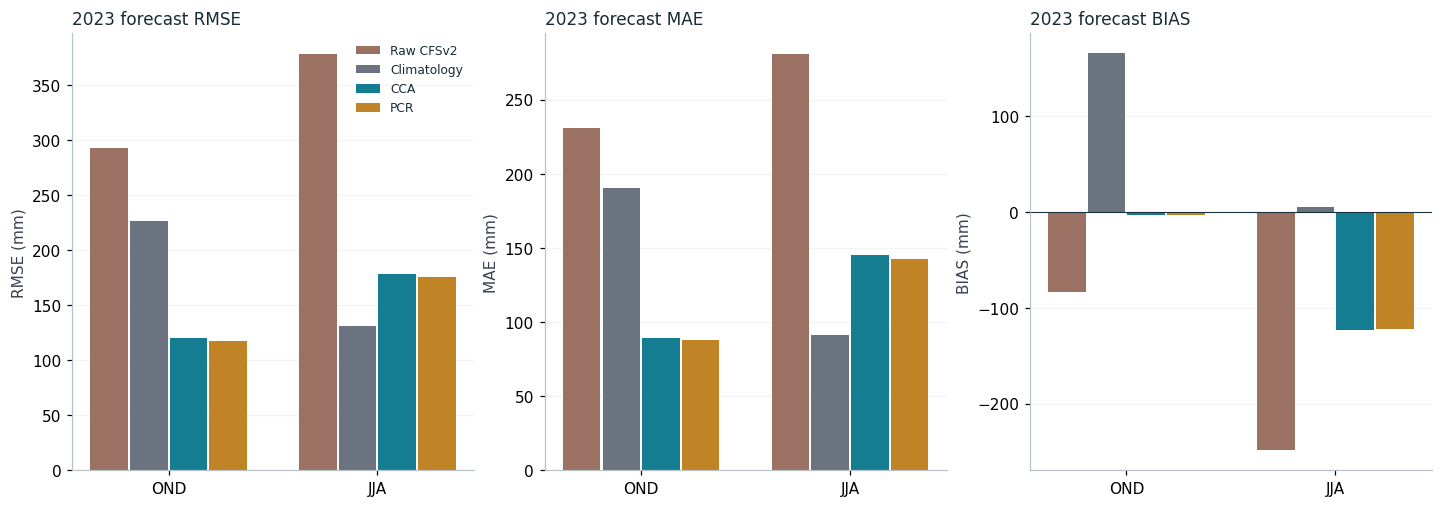

In [11]:
fig = fit.forecast_score_figure(scores)
display(fit.save_figure(fig, artifacts, "forecast-scores")); plt.close(fig)

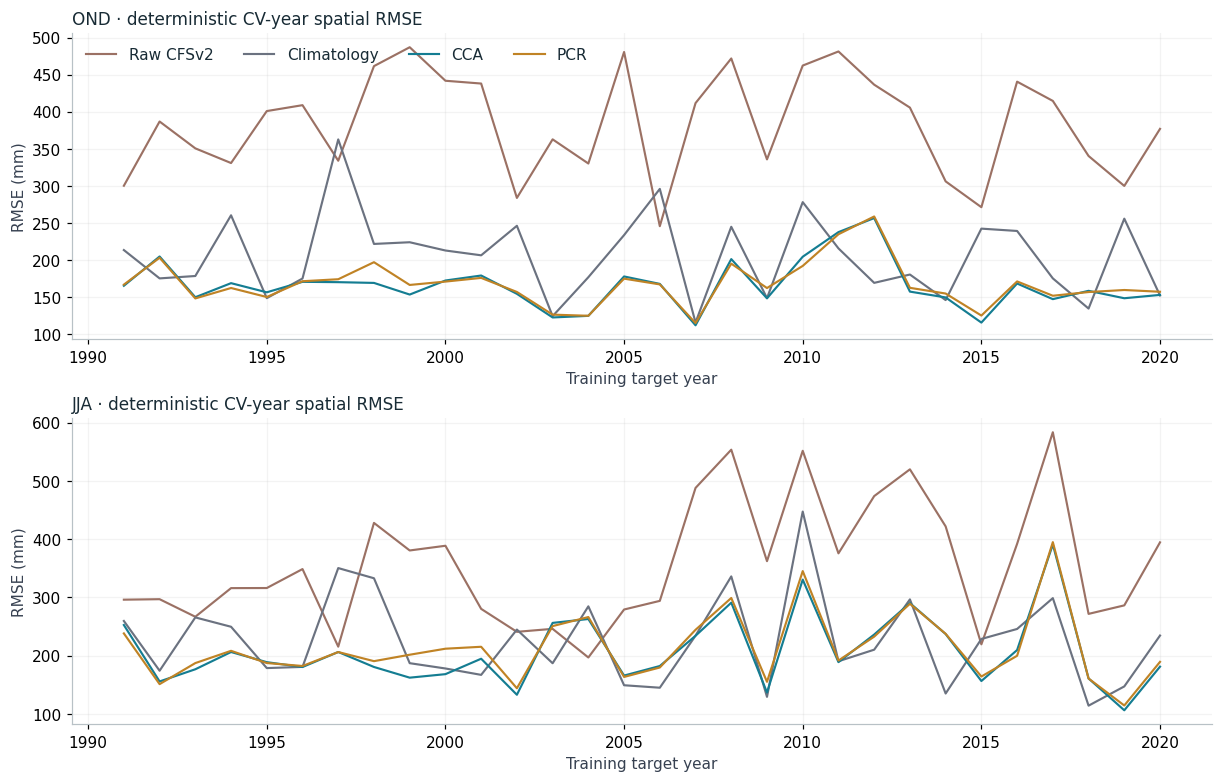

In [12]:
fig = fit.cv_figure(yearly)
display(fit.save_figure(fig, artifacts, "cv-residuals")); plt.close(fig)

## 8. Read model compression and paired patterns

Each spectrum has 30 entries, while only three EOFs are retained. In the wrapper's
merged pattern dataset, sharing a `Mode` axis can pad score/loading variables with
NaNs. The cleaned diagnostic files use separate EOF, CCA and spectrum axes.
Outside-support `-999` pattern values are decoded using the original input mask.

Native exported weights are **not** the field–score correlations displayed here.
The correlation maps are calculated explicitly from each printed training field
and its saved diagnostic score. Scores are standardized separately for display.
Paired sign changes in a pattern and its score do not change their product;
colours should not be read as a 2023 rainfall anomaly map.

,season,side,three_EOF_variance_percent,retained_EOF_modes,training_samples
0,OND,predictor,73.277595,3,30
1,OND,predictand,64.354505,3,30
2,JJA,predictor,63.789640,3,30
3,JJA,predictand,67.982988,3,30


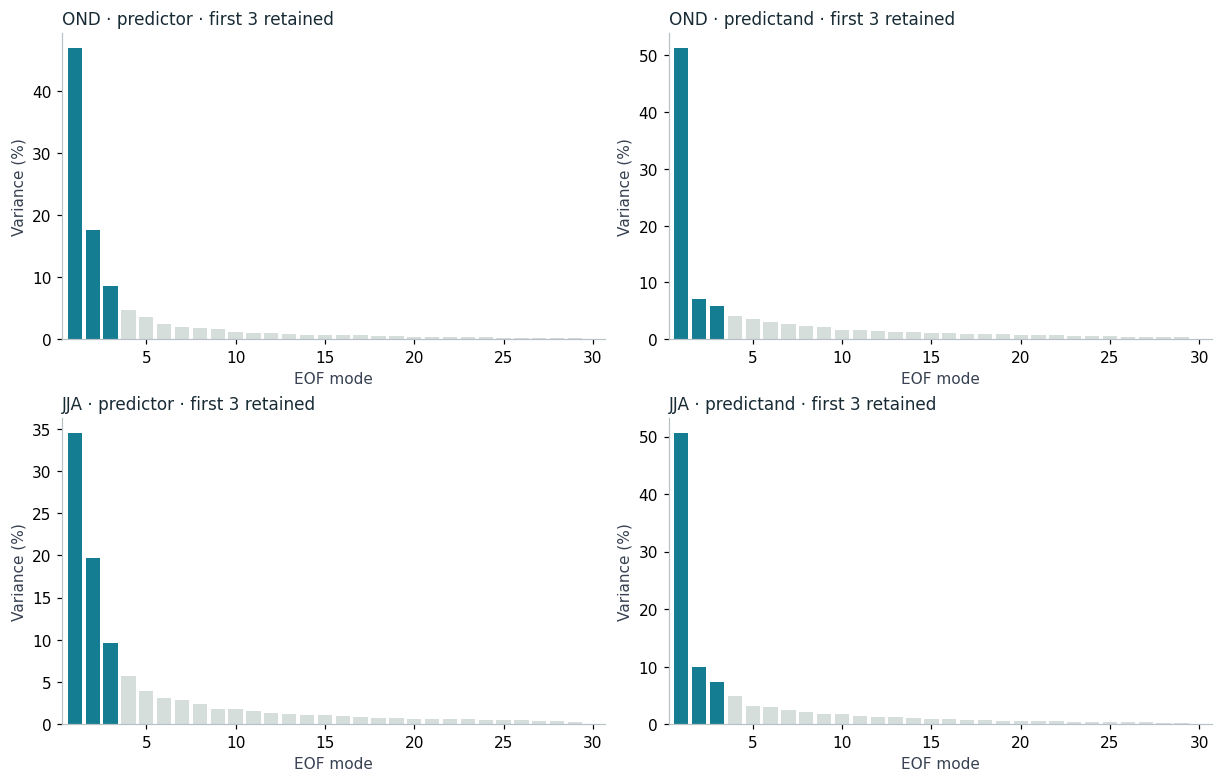

In [13]:
diagnostic_rows = []
for season in fit.SEASONS:
    for side in ["predictor", "predictand"]:
        d = results[season]["cca"][0][f"{side}-diagnostics"]
        diagnostic_rows.append({"season": season, "side": side,
            "three_EOF_variance_percent": float(d.cumulative_variance_percent.sel(spectrum_mode=3)),
            "retained_EOF_modes": 3, "training_samples": d.sizes["T"]})
diagnostic_table = pd.DataFrame(diagnostic_rows)
diagnostic_table.to_csv(artifacts / "diagnostic-summary.csv", index=False)
display(diagnostic_table)
fig = fit.scree_figure(results)
display(fit.save_figure(fig, artifacts, "scree")); plt.close(fig)

In [14]:
canonical_rows = []
for season in fit.SEASONS:
    d = results[season]["cca"][0]
    for mode in [1, 2]:
        r = np.corrcoef(d["predictor-diagnostics"].cca_score.sel(cca_mode=mode),
                        d["predictand-diagnostics"].cca_score.sel(cca_mode=mode))[0, 1]
        native = float(d["canonical-correlations"].native_correlation.sel(cca_mode=mode))
        np.testing.assert_allclose(r, native, atol=2e-6, rtol=0)
        canonical_rows.append({"season": season, "cca_mode": mode, "native_correlation": native, "recomputed_correlation": r})
canonical_table = pd.DataFrame(canonical_rows)
canonical_table.to_csv(artifacts / "canonical-correlations.csv", index=False)
display(canonical_table)

,season,cca_mode,native_correlation,recomputed_correlation
0,OND,1,0.945254,0.945254
1,OND,2,0.469345,0.469344
2,JJA,1,0.739972,0.739972
3,JJA,2,0.596654,0.596654


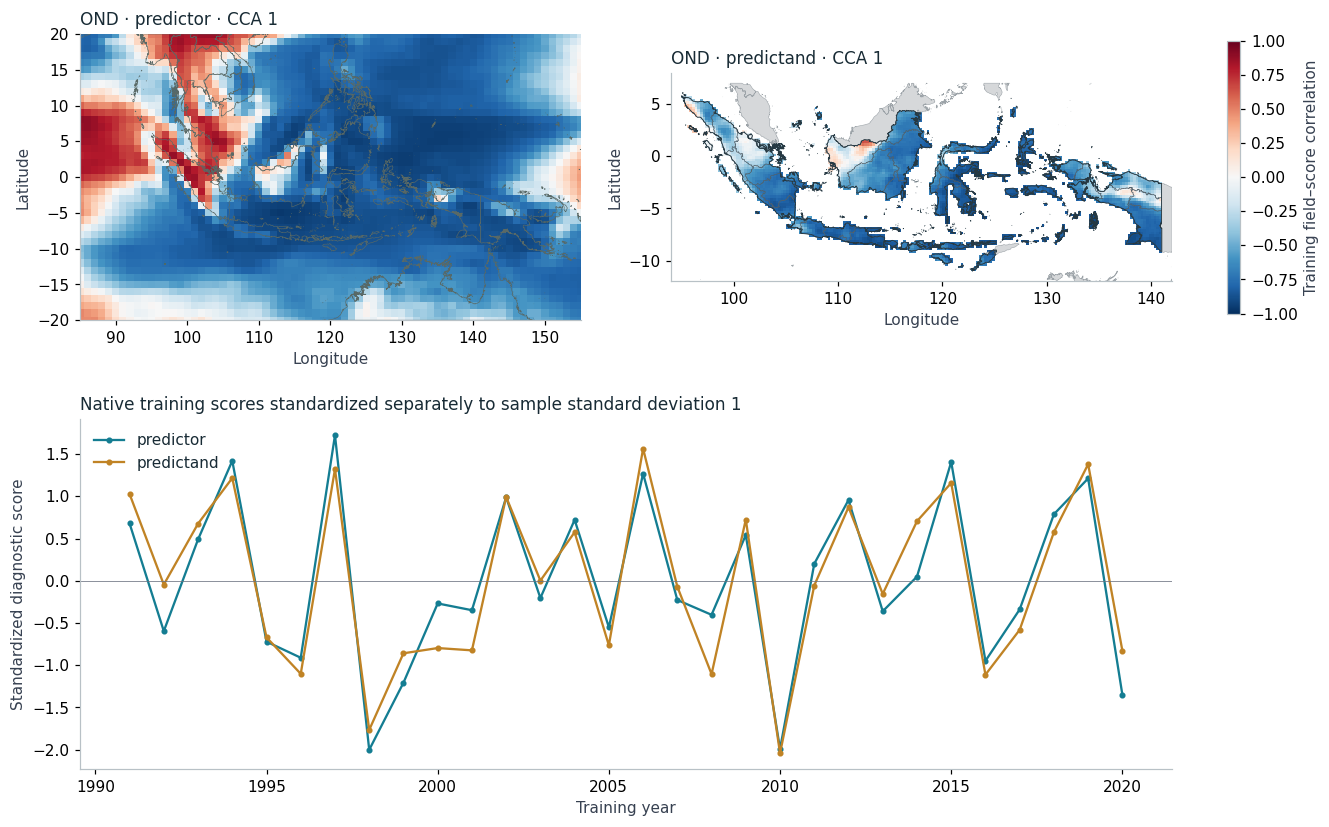

In [15]:
fig = fit.pattern_figure(results, data_dir, season="OND", kind="cca", mode=1)
display(fit.save_figure(fig, artifacts, "ond-cca-patterns")); plt.close(fig)

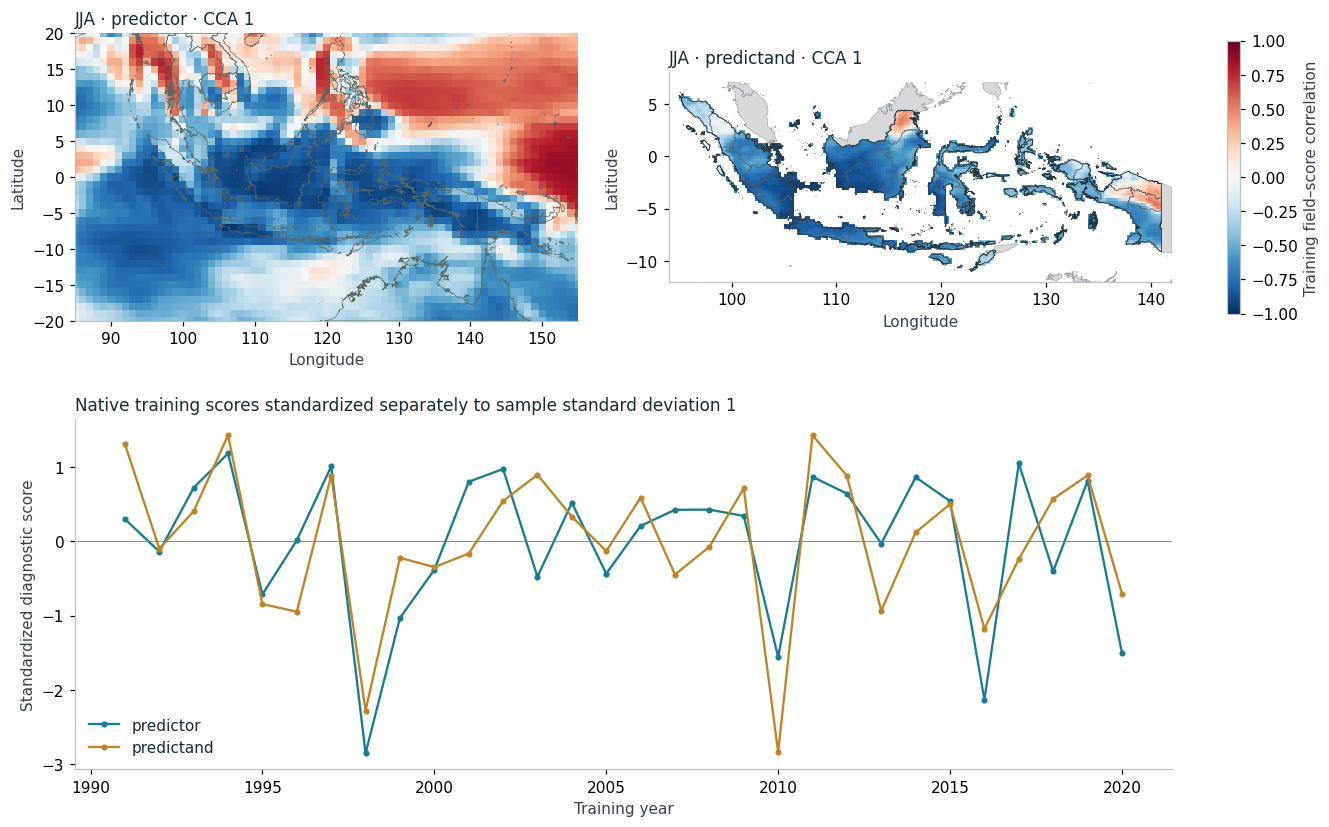

In [16]:
fig = fit.pattern_figure(results, data_dir, season="JJA", kind="cca", mode=1)
display(fit.save_figure(fig, artifacts, "jja-cca-patterns")); plt.close(fig)

These maps describe training relationships in model and observed rainfall.
They do not establish an ENSO/IOD mechanism or explain the cause of the JJA error.
High canonical correlation is not evidence of high forecast skill; see the
[official diagnostic guidance](https://cptplus.org/Help/Tools_Models_CCA.html).
The independent audit closely reproduces EOF directions and variance percentages,
but a small absolute eigenvalue-scale discrepancy remains unresolved. Amplitude
reconstruction is outside this lesson.

## 9. Return to the forecast errors

The same fitting workflow can improve on the raw model and still lose to a simple
climatology forecast. Inspect where the errors occur instead of identifying a
preferred method from attractive training maps. OND and JJA are selected examples;
their contrast does not establish a general relationship between training
canonical correlation and future performance.

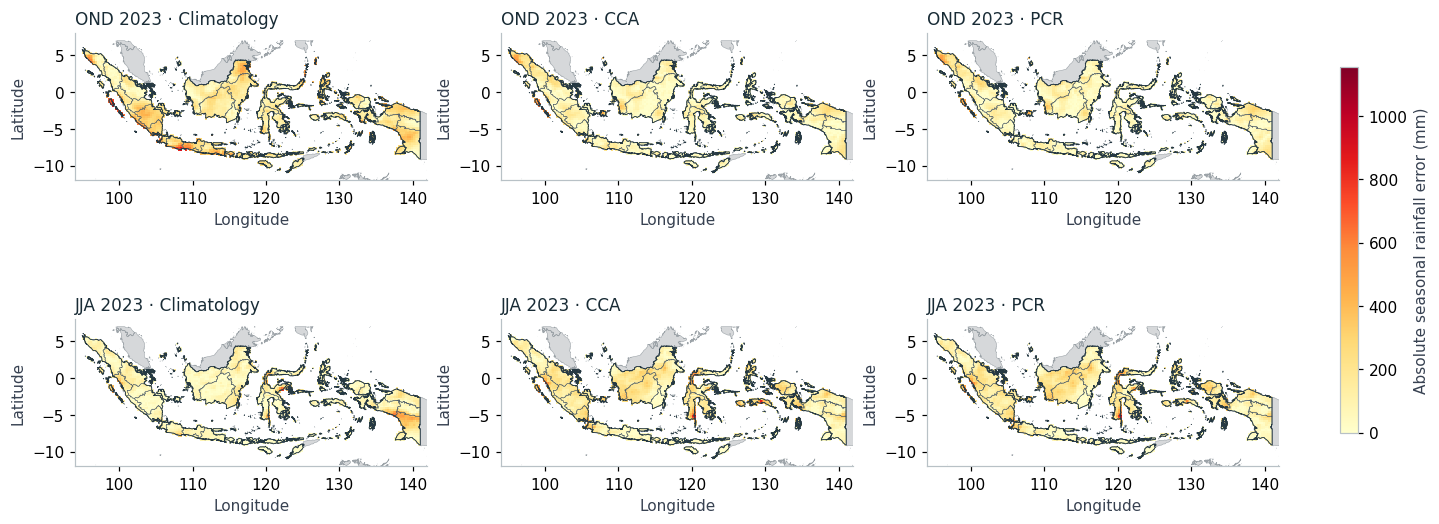

In [17]:
fig = fit.error_figure(comparison, data_dir)
display(fit.save_figure(fig, artifacts, "forecast-errors")); plt.close(fig)

## 10. Export a complete record

Every fit retains forecasts, deterministic hindcasts, native skill and all returned
pattern datasets, plus cleaned diagnostics and numerical control checks. The native
probability/variance outputs are preserved with their provenance, not used as
demonstrated probabilistic skill. Prepared inputs and frozen controls stay unchanged.
The story reads the presentation file generated here; it performs no model fitting
or aggregate score calculation in the browser.

In [18]:
summary = fit.presentation_data(root, artifacts, results, scores, yearly, comparison, input_table, runtime, offline)
print(f"Completed {len(summary['fits'])} isolated fits; exported {len(summary['netcdf_outputs'])} NetCDF files.")
print(f"Credential reads: {offline['credential_reads']}; remote connections: {offline['remote_connections']}.")
print("Saved forecasts, CV diagnostics, model patterns, tables and interactive-story data.")

Completed 4 isolated fits; exported 30 NetCDF files.
Credential reads: 0; remote connections: 0.
Saved forecasts, CV diagnostics, model patterns, tables and interactive-story data.


## Limits and references

This is a controlled retrospective learning exercise. The training and forecast
periods are separate, but the examples were selected using known outcomes. Fixed
mode counts are not demonstrated to be optimal. Spatial cells are dependent;
two seasons are not independent evidence of general operational performance.
Source-vintage and archive-transition cautions from the first case still apply.

- [IRI: CCA/PCR and validation](https://iri.columbia.edu/~awr/pycpt/seasonal-jupyterbook/html_2sep2023/cpt.html).
- [IRI: inspect patterns and diagnostics](https://iri.columbia.edu/~awr/pycpt/seasonal-jupyterbook/html_2sep2023/configuration.html).
- [EOF displays versus exported loadings](https://cptplus.org/Help/Tools_Models_YEOF.html).
- [CCA maps and canonical correlations](https://cptplus.org/Help/Tools_Models_CCA.html).
- [Project methods and limitations](../guides/methods.qmd).

## References {.unnumbered .reference-section}

1. IRI. *Guide to PyCPT 2 for Seasonal Climate Forecasts* (Jupyter Book, 2 September 2023 build): The Climate Predictability Tool (CPT). <https://iri.columbia.edu/~awr/pycpt/seasonal-jupyterbook/html_2sep2023/cpt.html>
2. IRI. *Guide to PyCPT 2 for Seasonal Climate Forecasts* (Jupyter Book, 2 September 2023 build): Configuring PyCPT 2.5. <https://iri.columbia.edu/~awr/pycpt/seasonal-jupyterbook/html_2sep2023/configuration.html>
3. IRI. *CPT-Core demonstration notebook* (`Demo/cptcore_demo.ipynb`). iri-pycpt/notebooks, commit 1c97531. <https://github.com/iri-pycpt/notebooks/blob/1c975316910b9e047ce685d9b8cdefb2c4b73551/Demo/cptcore_demo.ipynb>
4. CPT+. *444: CCA Maps* (CPT help). <https://cptplus.org/Help/Tools_Models_CCA.html> Same page name as on the former cpthelp.iri.columbia.edu, which did not resolve when checked on 10 November 2026.
5. CPT+. *443: Y Loadings and Scores* (CPT help). <https://cptplus.org/Help/Tools_Models_YEOF.html> Same page name as on the former cpthelp.iri.columbia.edu, which did not resolve when checked on 10 November 2026.
6. IRI Data Library. *NMME NCEP-CFSv2 hindcasts, PENTAD_SAMPLES_FULL, precipitation*. <https://iridl.ldeo.columbia.edu/SOURCES/.Models/.NMME/.NCEP-CFSv2/.HINDCAST/.PENTAD_SAMPLES_FULL/.prec/> Browsing Data Library pages requires signing in (checked 10 November 2026); PyCPT's data requests in this tutorial succeeded without a key.
7. Saha, S., Moorthi, S., Wu, X., et al. (2014). The NCEP Climate Forecast System Version 2. *Journal of Climate*, 27(6), 2185-2208. <https://doi.org/10.1175/JCLI-D-12-00823.1>
8. Climate Hazards Center, UC Santa Barbara. *CHIRPS: Rainfall Estimates from Rain Gauge and Satellite Observations* (CHIRPS version 3.0 page). <https://www.chc.ucsb.edu/data/chirps3>
9. Funk, C., Peterson, P., Landsfeld, M., et al. (2014). *A quasi-global precipitation time series for drought monitoring*. U.S. Geological Survey Data Series 832. <https://doi.org/10.3133/ds832>